# <span style="color:red"> Lab 9 - Predicting the Next Word in Hotel Reviews  </span>

<font size = "4">

- Suppose you’re reading a hotel review and get to the phrase “We thought the room ...”. What word would you expect to come next?

- To answer this question, we'll apply a (very primitive) predictive language model. LLMs use much more sophisticated approaches. Check out DATASCI 340 or [this free textbook](https://web.stanford.edu/~jurafsky/slp3/) for more info.

- We'll estimate a very simple probability distribution from a **trigram** (3-gram) language model, a specific case of the N-gram language model

$\qquad$ <img src="files_lab9/trigram.png" alt="drawing" width="500"/>


<font size = "2">

(quote taken from Chapter 3 of the textbook linked above)

<font size = "4">

Let's read in a dataset containing hotel reviews ([taken from here](https://www.kaggle.com/datasets/datafiniti/hotel-reviews)). The most important column will be "review" which contains text reviewing someone's stay at a hotel:


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

hotels = pd.read_csv("files_lab9/Hotel_Reviews.csv")

display(hotels)
display(hotels[["review", "rating"]].head())

,id,dateAdded,dateUpdated,address,categories,primaryCategories,city,country,keys,latitude,...,reviews.dateSeen,rating,reviews.sourceURLs,review,reviews.title,reviews.userCity,reviews.userProvince,reviews.username,sourceURLs,websites
0,AVwc252WIN2L1WUfpqLP,2016-10-30T21:42:42Z,2018-09-10T21:06:27Z,5921 Valencia Cir,"Hotels,Hotels and motels,Hotel and motel reser...",Accommodation & Food Services,Rancho Santa Fe,US,us/ca/ranchosantafe/5921valenciacir/359754519,32.990959,...,"2016-08-03T00:00:00Z,2016-07-26T00:00:00Z,2016...",5.0,https://www.hotels.com/hotel/125419/reviews%20/,Our experience at Rancho Valencia was absolute...,Best romantic vacation ever!!!!,NaN,NaN,Paula,http://www.hotels.com/ho125419/%25252525253Flo...,http://www.ranchovalencia.com
1,AVwc252WIN2L1WUfpqLP,2016-10-30T21:42:42Z,2018-09-10T21:06:27Z,5921 Valencia Cir,"Hotels,Hotels and motels,Hotel and motel reser...",Accommodation & Food Services,Rancho Santa Fe,US,us/ca/ranchosantafe/5921valenciacir/359754519,32.990959,...,"2016-08-02T00:00:00Z,2016-08-26T00:00:00Z,2016...",5.0,https://www.hotels.com/hotel/125419/reviews%20/,Amazing place. Everyone was extremely warm and...,Sweet sweet serenity,NaN,NaN,D,http://www.hotels.com/ho125419/%25252525253Flo...,http://www.ranchovalencia.com
2,AVwc252WIN2L1WUfpqLP,2016-10-30T21:42:42Z,2018-09-10T21:06:27Z,5921 Valencia Cir,"Hotels,Hotels and motels,Hotel and motel reser...",Accommodation & Food Services,Rancho Santa Fe,US,us/ca/ranchosantafe/5921valenciacir/359754519,32.990959,...,"2016-11-15T00:00:00Z,2016-08-23T00:00:00Z,2016...",5.0,https://www.hotels.com/hotel/125419/reviews%20/,We booked a 3 night stay at Rancho Valencia to...,Amazing Property and Experience,NaN,NaN,Ron,http://www.hotels.com/ho125419/%25252525253Flo...,http://www.ranchovalencia.com
3,AVwdOclqIN2L1WUfti38,2015-11-28T19:19:35Z,2018-09-10T21:06:16Z,7520 Teague Rd,"Hotels,Hotels and motels,Travel agencies and b...",Accommodation & Food Services,Hanover,US,us/md/hanover/7520teaguerd/-2043779672,39.155929,...,"2016-05-21T00:00:00Z,2016-07-31T00:00:00Z",2.0,https://www.tripadvisor.com/Hotel_Review-g4118...,Currently in bed writing this for the past hr ...,"Never again...beware, if you want sleep.",Richmond,VA,jaeem2016,http://www.yellowbook.com/profile/aloft-arunde...,http://www.starwoodhotels.com/alofthotels/prop...
4,AVwdOclqIN2L1WUfti38,2015-11-28T19:19:35Z,2018-09-10T21:06:16Z,7520 Teague Rd,"Hotels,Hotels and motels,Travel agencies and b...",Accommodation & Food Services,Hanover,US,us/md/hanover/7520teaguerd/-2043779672,39.155929,...,2016-07-31T00:00:00Z,5.0,https://www.tripadvisor.com/Hotel_Review-g4118...,I live in Md and the Aloft is my Home away fro...,ALWAYS GREAT STAY...,Laurel,MD,MamaNiaOne,http://www.yellowbook.com/profile/aloft-arunde...,http://www.starwoodhotels.com/alofthotels/prop...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9994,AVwd4TMv_7pvs4fz-Ers,2016-03-24T11:44:15Z,2018-01-01T00:00:46Z,215 S Pacific St,"Hotel,Hotels,Lodging,Motels",Accommodation & Food Services,Rockaway Beach,US,us/or/rockawaybeach/215spacificst/-1035432852,45.611260,...,2016-03-23T00:00:00Z,3.0,http://www.tripadvisor.com/Hotel_Review-g52043...,It is hard for me to review an oceanfront hote...,Picture Window Ocean View!,Wildwood,GA,LASH0211,https://www.tripadvisor.com/Hotel_Review-g5204...,http://www.oregonsilversands.com
9995,AVwdRp4DIN2L1WUfuGZZ,2015-10-26T23:03:02Z,2018-01-01T00:00:44Z,669 Route 6a,"Hotel,Hotels",Accommodation & Food Services,East Sandwich,US,us/ma/eastsandwich/669route6a/-1480952475,41.729390,...,"2016-05-13T00:00:00Z,2016-03-21T00:00:00Z",4.0,https://www.tripadvisor.com/Hotel_Review-g4154...,"I live close by, and needed to stay somewhere ...","Clean, comfortable and quiet",East Sandwich,MA,Gennaker,https://www.tripadvisor.com/Hotel_Review-g4154...,http://www.sandyneck.com
9996,AVwd1TbkByjofQCxs6FH,2016-06-11T03:12:23Z,2018-01-01T00:00:44Z,702 W Appleway Ave,"Hotel,Hotel, Motel, and Building,Hotels,Lodg

,review,rating
0,Our experience at Rancho Valencia was absolute...,5.0
1,Amazing place. Everyone was extremely warm and...,5.0
2,We booked a 3 night stay at Rancho Valencia to...,5.0
3,Currently in bed writing this for the past hr ...,2.0
4,I live in Md and the Aloft is my Home away fro...,5.0




### 1. Split the reviews into words

<font size = "4">

Each review starts out as one long string. The code below uses `.str.findall()` to pull out the individual words, which we’ll call "tokens". This is added as an additional column to the DataFrame.

The **regular expression** pattern `[A-Za-z']+` looks for groups of letters and straight apostrophes. The apostrophe lets us treat words like "don't" as a single token. We’ve already written the pattern for you:

In [2]:
hotels["tokens"] = hotels["review"].str.findall("[A-Za-z']+")
display(hotels[["review", "tokens"]].head())

print("Each entry of 'review' column is a:", type(hotels.loc[0, "review"]))
print("Each entry of 'tokens' column is a:", type(hotels.loc[0, "tokens"]))

,review,tokens
0,Our experience at Rancho Valencia was absolute...,"[Our, experience, at, Rancho, Valencia, was, a..."
1,Amazing place. Everyone was extremely warm and...,"[Amazing, place, Everyone, was, extremely, war..."
2,We booked a 3 night stay at Rancho Valencia to...,"[We, booked, a, night, stay, at, Rancho, Valen..."
3,Currently in bed writing this for the past hr ...,"[Currently, in, bed, writing, this, for, the, ..."
4,I live in Md and the Aloft is my Home away fro...,"[I, live, in, Md, and, the, Aloft, is, my, Hom..."


Each entry of 'review' column is a: <class 'str'>
Each entry of 'tokens' column is a: <class 'list'>



### Exercise 1 — Make all words lower-case.

<font size = "4">

We want `Room` and `room` to count as the same word. Try running the next cell to see what `.lower()` does to a string.

Then finish `lower_list`. It takes in a **list** of words (strings) as input, and returns a new list with each word in lowercase. Use `.apply()` to run your function on the series `hotels["tokens"]`, save the result back to that column. Then display the first few rows.

In [3]:
word = "Room"
print(word)
print(word.lower())
print()
word2 = "HoLiDaY"
print(word2)
print(word2.lower())

Room
room

HoLiDaY
holiday


In [4]:

def lower_list(lst):
    # lst is a list of strings
    # return a new list with the same strings, but lowercase
    new_lst = []
    for i in lst:
        new_lst.append(i.lower())

    return new_lst



# Apply lower_list to the "tokens" column, and then overwrite it with the lowercase version

hotels["tokens"] = hotels["tokens"].apply(lower_list)

display(hotels[["review", "tokens"]].head())        # all strings in "tokens" should be lowercase now

,review,tokens
0,Our experience at Rancho Valencia was absolute...,"[our, experience, at, rancho, valencia, was, a..."
1,Amazing place. Everyone was extremely warm and...,"[amazing, place, everyone, was, extremely, war..."
2,We booked a 3 night stay at Rancho Valencia to...,"[we, booked, a, night, stay, at, rancho, valen..."
3,Currently in bed writing this for the past hr ...,"[currently, in, bed, writing, this, for, the, ..."
4,I live in Md and the Aloft is my Home away fro...,"[i, live, in, md, and, the, aloft, is, my, hom..."


## 2. Create trigrams

<font size = "4">

A *trigram* is a group of three words in a row. Take the sentence “this was a very bad hotel.” Start with the first three words, then move over one word at a time. You’ll get:

- `("this", "was", "a")`
- `("was", "a", "very")`
- `("a", "very", "bad")`
- `("very", "bad", "hotel")`

We’ll store each trigram as a **tuple** so pandas can use it as an index label when we count how often it appears. The next cell shows how this works for the first hotel review.

In [5]:
words = hotels["tokens"].iloc[0]  # get list of words from row 0
print(words)
N = len(words)

trigram_list = []
for i in range(N-2):
    trigram = (words[i], words[i+1], words[i+2]) # define trigram as a tuple
    trigram_list.append(trigram)

trigram_list

['our', 'experience', 'at', 'rancho', 'valencia', 'was', 'absolutely', 'perfect', 'from', 'beginning', 'to', 'end', 'we', 'felt', 'special', 'and', 'very', 'happy', 'during', 'our', 'stayed', 'i', 'would', 'come', 'back', 'in', 'a', 'heart', 'beat']


[('our', 'experience', 'at'),
 ('experience', 'at', 'rancho'),
 ('at', 'rancho', 'valencia'),
 ('rancho', 'valencia', 'was'),
 ('valencia', 'was', 'absolutely'),
 ('was', 'absolutely', 'perfect'),
 ('absolutely', 'perfect', 'from'),
 ('perfect', 'from', 'beginning'),
 ('from', 'beginning', 'to'),
 ('beginning', 'to', 'end'),
 ('to', 'end', 'we'),
 ('end', 'we', 'felt'),
 ('we', 'felt', 'special'),
 ('felt', 'special', 'and'),
 ('special', 'and', 'very'),
 ('and', 'very', 'happy'),
 ('very', 'happy', 'during'),
 ('happy', 'during', 'our'),
 ('during', 'our', 'stayed'),
 ('our', 'stayed', 'i'),
 ('stayed', 'i', 'would'),
 ('i', 'would', 'come'),
 ('would', 'come', 'back'),
 ('come', 'back', 'in'),
 ('back', 'in', 'a'),
 ('in', 'a', 'heart'),
 ('a', 'heart', 'beat')]

### Exercise 2 — Build trigrams for every review

<font size = "4">

The example above builds trigrams for the first review. Turn that code into a function called `get_trigrams` that takes a list of words and returns its trigrams in order. If the list has fewer than three words, the function should return an **empty list**.

Use `.apply()` to run `get_trigrams` on the `tokens` column. Save the result in a new column called `trigrams` and display the first few rows.

In [16]:
def get_trigrams(words):
    trigram_list = []
    N = len(words)
    for i in range(N-2):
        trigram = (words[i], words[i+1], words[i+2]) # define trigram as a tuple
        trigram_list.append(trigram)
    return trigram_list


hotels["trigrams"] = hotels["tokens"].apply(get_trigrams)

# Use .apply() to create the trigrams column and display the first few rows.

### 3. Count the trigrams

#### 3a. Put each trigram on its own row

<font size = "4">

Each row in `hotels["trigrams"]` holds a list of trigrams from one review: 

In [17]:
hotels["trigrams"].iloc[0]

[('our', 'experience', 'at'),
 ('experience', 'at', 'rancho'),
 ('at', 'rancho', 'valencia'),
 ('rancho', 'valencia', 'was'),
 ('valencia', 'was', 'absolutely'),
 ('was', 'absolutely', 'perfect'),
 ('absolutely', 'perfect', 'from'),
 ('perfect', 'from', 'beginning'),
 ('from', 'beginning', 'to'),
 ('beginning', 'to', 'end'),
 ('to', 'end', 'we'),
 ('end', 'we', 'felt'),
 ('we', 'felt', 'special'),
 ('felt', 'special', 'and'),
 ('special', 'and', 'very'),
 ('and', 'very', 'happy'),
 ('very', 'happy', 'during'),
 ('happy', 'during', 'our'),
 ('during', 'our', 'stayed'),
 ('our', 'stayed', 'i'),
 ('stayed', 'i', 'would'),
 ('i', 'would', 'come'),
 ('would', 'come', 'back'),
 ('come', 'back', 'in'),
 ('back', 'in', 'a'),
 ('in', 'a', 'heart'),
 ('a', 'heart', 'beat')]

<font size = "4">

We want each trigram to have its own row. We can use the `.explode()` method to "unravel" each list and gives each element its own row. Compare the output before and after the call below, and note how the number of rows has increased. The index labels repeat because pandas keeps the original review’s row label for each trigram it came from.

In [18]:
display(hotels["trigrams"])


exploded_trigrams = hotels["trigrams"].explode()
display(exploded_trigrams)

0       [(our, experience, at), (experience, at, ranch...
1       [(amazing, place, everyone), (place, everyone,...
2       [(we, booked, a), (booked, a, night), (a, nigh...
3       [(currently, in, bed), (in, bed, writing), (be...
4       [(i, live, in), (live, in, md), (in, md, and),...
                              ...                        
9994    [(it, is, hard), (is, hard, for), (hard, for, ...
9995    [(i, live, close), (live, close, by), (close, ...
9996    [(rolled, in, laid), (in, laid, out), (laid, o...
9997    [(absolutely, terrible, i), (terrible, i, was)...
9998    [(filthy, outdated, noisy), (outdated, noisy, ...
Name: trigrams, Length: 9999, dtype: object

0             (our, experience, at)
0          (experience, at, rancho)
0            (at, rancho, valencia)
0           (rancho, valencia, was)
0       (valencia, was, absolutely)
                   ...             
9998             (enemy, next, day)
9998                (next, day, we)
9998              (day, we, needed)
9998          (we, needed, medical)
9998        (needed, medical, help)
Name: trigrams, Length: 570084, dtype: object

<font size = "4">

What if a review only says “Awesome, Overall.”? Two words aren’t enough to make a trigram, so the list of trigrams is empty: after executing `.explode()` the empty list becomes `nan`:

In [19]:
print(hotels["review"].loc[46])
print(hotels["trigrams"].loc[46])
print(exploded_trigrams.loc[46])

Awesome, Overall
[]
nan


<font size = "4">

To remove the "nans", we'll use the `.dropna()` method to remove these missing values. Notice how the number of rows decreases:

In [20]:
print(len(exploded_trigrams))

all_trigrams = exploded_trigrams.dropna()
print(len(all_trigrams))

570084
570010


### 3b. Find the most common trigrams
<font size = "4">

Now that each trigram has its own row, use `.value_counts()` to see how many times each one appears. Save the result as `tri_counts` and display the five most common trigrams.

In [22]:
# Save the counts as tri_counts and display the five most common trigrams.

tri_counts = all_trigrams.value_counts()
print(tri_counts.iloc[:5])

trigrams
(the, room, was)      963
(the, front, desk)    671
(the, staff, was)     613
(the, hotel, is)      420
(the, hotel, was)     411
Name: count, dtype: int64


### 3c. Turn counts into proportions
<font size = "4">
The counts tell us how many times each trigram appeared. Since our language model uses probabilities, we want to know how often each trigram appears out of all the trigrams we found. For example, if a trigram shows up 5 times out of 100, its proportion is 0.05.

Run `.value_counts()` again with `normalize=True` to get those proportions. Together, they form a probability distribution over the trigrams in our dataset. Save the result as `tri_probs` and display the first five entries.

In [24]:
# Save the proportions as tri_probs and display the first five entries.

tri_probs = all_trigrams.value_counts(normalize=True)
print(tri_probs[:5])

trigrams
(the, room, was)      0.001689
(the, front, desk)    0.001177
(the, staff, was)     0.001075
(the, hotel, is)      0.000737
(the, hotel, was)     0.000721
Name: proportion, dtype: float64


### 3d. Plot the 15 most common trigrams
<font size = "4">

Take the first 15 entries from `tri_probs` and save them as `top_15`. You can use `.head()` or `.iloc`.

Call the `.plot()` method from `top_15` with `kind="bar"` and `figsize=(12, 4)`. Give the plot a title, label the y-axis "Probability", and don't forget to call `plt.show()`!

Are the x-axis labels hard to read vertically? You can use the following command (before plt.show()) to make them more readable: `plt.xticks(rotation=45)`

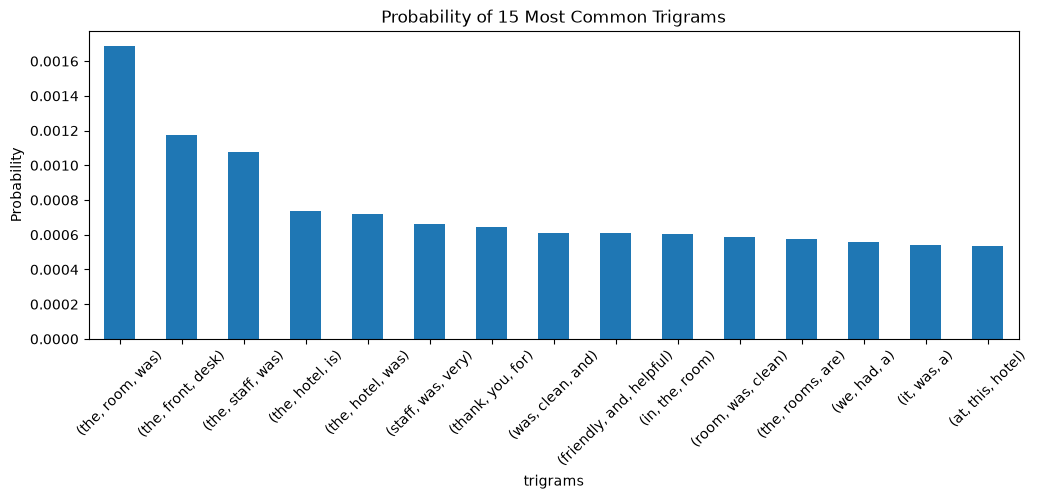

In [28]:
# Select the top 15 trigrams.
top_15 = tri_probs[:15]
# Make the bar plot.

top_15.plot(kind="bar", figsize=(12, 4))

# Add a title and y-axis label, then show the plot.
plt.title("Probability of 15 Most Common Trigrams")
plt.ylabel("Probability")
plt.xticks(rotation=45)
plt.show()

## 4. Predict the next word

### Exercise 4 — What comes after “the room”?

<font size = "4">

Let’s go back to “We thought the room …”. The starter code marks the trigrams that begin with `("the", "room")`. Then a function `check_for_prefix` is written that returns `True` if the first two words of a trigram coincide with the prefix. 

If we use the Series `all_trigrams`, we can simply use `.apply` to get a Boolean mask where each entry is `True` when the trigram starts with "the room":

In [29]:
prefix = ("the", "room") # predict next word based on these two

def check_for_prefix(trigram):
    # True or False: first two elements of trigram are "the" and "room"
    return trigram[:2] == prefix

bool_mask = all_trigrams.apply(check_for_prefix)

bool_mask

0       False
0       False
0       False
0       False
0       False
        ...  
9998    False
9998    False
9998    False
9998    False
9998    False
Name: trigrams, Length: 570010, dtype: bool

<font size = "4">

Unfortunately, we can't use `bool_mask` with `tri_probs` because the indices don't match. We also can't use `.apply` with `tri_probs` because the trigrams are the **index** of the Series, while the data are the probabilities (floating point numbers).

Since `tri_probs.index` are the actual trigrams, we use a method that is similar to `.apply`. It's called `.map`:

In [30]:
index_mask = tri_probs.index.map(check_for_prefix)

index_mask

Index([ True, False, False, False, False, False, False, False, False, False,
       ...
       False, False, False, False, False, False, False, False, False, False],
      dtype='bool', name='trigrams', length=363387)

<font size = "4">

Use `index_mask` to extract all the probabilities in `tri_probs` corresponding to trigrams that start with "the room". Name the resulting variable `candidate_trigrams`.

**Hint:** What if `tri_probs` were a NumPy array? It works the same way here.

In [ ]:
# your code here


<font size = "4">

Execute the `.sum()` method from `candidate_trigrams`. Does it sum to 1 (or a number very close to 1)? If not, we don't have a true probability distribution anymore.

Change the values of `candidate_trigrams` so that its values sum to 1 (or close to it), without changing the ratios between them. For example, if one trigram was twice as likely as another before, it should still be twice as likely afterward. After changing them, run `candidate_trigrams.sum()` again to check your work.

**Hint:** The sum of the sequence (1, 1, 1) is 1 + 1 + 1 = 3. How would you change the sequence so that all 3 numbers are still equal, but they sum to 1 instead of 3? How would you change the sequence (1, 2, 4) so that the second number is still double the first, the third number is still double the second, but they sum to 1 instead of 7?

In [ ]:
# your code here



<font size = "4">

The probabilities should be sorted from highest to lowest at this point. Display the 10 most likely trigrams starting with "the room". Print the most likely next word and its probability. The next word is the third word in the top trigram.

In [ ]:
# your code here


<font size = "4">

Repeat the process with the prefix "front desk". What is the most likely next word?

In [ ]:
# your code here
